# Quantum algorithm for second-harmonic generation
## Illustrative QSP and the Gao-state hybrid for NiI₂

A 1030 nm field generates second-harmonic light at 515 nm. This mini-project
implements quantum response circuits, tests them against classical calculations,
and asks whether the current material approximation reproduces measured SHG.

The notebook contains one illustrative model and one material model:

1. **Method:** implement the spectral-filter/QSP construction for illustrative
   optical levels with an independent density-matrix reference.
2. **Material calculation:** Gao's spin Hamiltonian and fixed magnetic parameters
   determine a correlated single-domain-conditioned density at 1.63 K. A retained
   electronic model supplies the optical response operator. Their explicit hybrid
   is the current supported material approximation.
3. **Comparison:** separate identical-input circuit accuracy, electronic reduction,
   experimental disagreement and computational costs; state the conditions for
   potential quantum advantage.
4. **Summary:** established results and unresolved physical/numerical limitations.

**Magnetic and optical Hamiltonians have different roles.** Gao supplies the
low-energy spin model; Fan's electronic energies and point-orbital dipoles remain
in the optical denominators. Calling every optical parameter a Gao input would
be incorrect. The resulting hybrid is not an author-validated optical NiI₂ model.

**Observable:** a complex microscopic coefficient β multiplying E₊² in the
2ω dipole, and its intensity proxy |β|². The experimental comparison fits one
shared detector gain and azimuth, so absolute bulk susceptibility is not tested.
A seven-site state-conditioning source and an incomplete optical basis remain
assumptions. No accurate bulk prediction or quantum speedup is established.

Sources: [Kharazi et al.](https://arxiv.org/html/2404.01454v1),
[Gao et al.](https://doi.org/10.1038/s41586-024-07678-5),
[Fan et al.](https://doi.org/10.1038/s41524-026-02184-w),
[Mou and Winter](https://arxiv.org/html/2602.02872v1).

### Paper scope, versions and library credits

**Chosen method:** Kharazi, Stetina, Ko, Low and Whaley, *An efficient quantum
algorithm for generation of ab initio n-th order susceptibilities for non-linear
spectroscopies*, **arXiv:2404.01454v1 (1 April 2024)**. Implementation references
are to that version: II.3 (LCU), II.4 (QSP), III.1.2 (spectral indicators),
III.1.3 (non-unitary Hadamard test), and III.2 (higher-order products).
[Versioned source](https://arxiv.org/html/2404.01454v1).

**What is implemented here:** custom Pauli-LCU assembly, bounded polynomial
construction, numerical phase fitting, repeated-signal QSP circuits, coherent
dipole/filter products and complex readout on a small optical example. Window
locations and the ground state are supplied; adaptive spectral discovery and
fault-tolerant chemistry oracles are omitted. The Gao-state hybrid is a project
extension using dense resolvent blocks, not full-space execution of the paper.
Its magnetic and electronic parameter transcriptions are credited in Part 2.
The project is a spectral-filter/nonlinear-response construction, not merely
the Hamiltonian-simulation exercise covered in class.

**Library support:** Qiskit supplies QuantumCircuit, gates, StatePreparation,
Pauli decomposition, Operator/Statevector simulation and transpilation. NumPy
supplies matrix/polynomial arithmetic; SciPy supplies least-squares phase
optimization, sparse eigensolvers/LU factorizations, matrix exponentials and
special functions. Matplotlib/IPython handle plots and presentation. The
project assembles the chosen method; it does not call a complete built-in
QSP/nonlinear-spectroscopy algorithm. No third-party project implementation
is vendored; mathematical definitions and transcribed matrices follow the
cited papers.

In [1]:
# Always load the source beside this notebook, including in a reused VS Code kernel.
import importlib
import inspect
import os
import sys
from pathlib import Path

_candidates = []
if os.environ.get("NII2_PROJECT_ROOT"):
    _candidates.append(Path(os.environ["NII2_PROJECT_ROOT"]).expanduser())
_notebook_path = globals().get("__vsc_ipynb_file__")
if _notebook_path:
    _notebook_parent = Path(_notebook_path).expanduser().resolve().parent
    _candidates.extend([_notebook_parent, *_notebook_parent.parents])
_candidates.extend([Path.cwd(), *Path.cwd().parents])
ROOT = next(
    (
        p.resolve()
        for p in _candidates
        if (p / "pyproject.toml").is_file() and (p / "src/nii2_shg/model.py").is_file()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError(
        "Open this notebook from miniproject2, or set NII2_PROJECT_ROOT to that folder before Run All."
    )
_project_source = ROOT / "src"
if str(_project_source) in sys.path:
    sys.path.remove(str(_project_source))
sys.path.insert(0, str(_project_source))
for _module_name in list(sys.modules):
    if _module_name == "nii2_shg" or _module_name.startswith("nii2_shg."):
        del sys.modules[_module_name]
importlib.invalidate_caches()
from nii2_shg import material_response as _response_module

_required_response_keywords = {"output_mu", "initial_rho", "second_gamma_factor"}
if not _required_response_keywords.issubset(
    inspect.signature(_response_module.classical_response).parameters
):
    raise RuntimeError(
        f"The project code at {_response_module.__file__} is out of date; update miniproject2 before running this notebook."
    )
if (
    Path(_response_module.__file__).resolve()
    != (_project_source / "nii2_shg/material_response.py").resolve()
):
    raise RuntimeError(
        "A different nii2_shg installation was loaded instead of this project source."
    )
classical_response = _response_module.classical_response
quantum_response = importlib.import_module("nii2_shg.response_circuit").quantum_response
print("Project source:", _project_source)
print("Classical response loaded from:", _response_module.__file__)

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display
from qiskit.quantum_info import Statevector

from nii2_shg.benchmarks import run_benchmark
from nii2_shg.circuits import dipole_block, overlap_circuit
from nii2_shg.model import (
    OpticalModel,
    beta_from_products,
    classical_beta,
    photon_energy,
)
from nii2_shg.qsp import (
    design_window,
    qsp_product,
    qsp_sequence,
    qsp_signal_circuit,
    scalar_qsp,
    window,
)

OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
model = OpticalModel(eta=1.0)
fundamental_ev = photon_energy(1030)
gamma_toy_ev = 0.05
print(f"1030 nm fundamental: {fundamental_ev:.6f} eV; harmonic: 515 nm")

Project source: /Users/xinyuepeng/Quantum Computing/miniproject2/src
Classical response loaded from: /Users/xinyuepeng/Quantum Computing/miniproject2/src/nii2_shg/material_response.py


1030 nm fundamental: 1.203730 eV; harmonic: 515 nm


# 1. Implement the spectral-filter method for illustrative SHG

This first part isolates algorithm correctness using known levels and dipoles.
It builds QSP filters and coherent optical products explicitly, then checks all
second-order terms against a classical reference. The levels are illustrative;
material-derived electronic parameters enter in Part 2. Numerical comparisons
use identical field, frequency, damping and normalization conventions.

## 1.1 Define the optical model and observable

The laser does not determine material levels. Use illustrative eigenenergies
$E_g=0$, $E_1=1.50$, $E_2=2.70$ eV, with an uncoupled padding state at 4 eV.
For one polarization, the active dipole is
$$
\mu=\begin{pmatrix}0&0.8&0.3s\\0.8&0&0.5\\0.3s&0.5&0\end{pmatrix}
\quad[e\,\text{Å}],
$$
where $s$ is dimensionless inversion breaking. The legacy model keyword `eta`
means this $s$ only. **It is unrelated to Mou's broadening eta in eV.**
At $s=0$, parity $(+,-,+)$ forbids the $g\leftrightarrow2$ transition.
These parameters are not fitted NiI₂ values.

Use $H(t)=H_0-\mu E(t)$ and $E(t)=E_+e^{-i\omega t}+\mathrm{c.c.}$.
Report $\beta$ multiplying $E_+^2$ in the dipole at $2\omega$, in
$(e\,\text{Å})^3/\mathrm{eV}^2$. The plotted $|\beta|^2$ is a microscopic
intensity proxy, not bulk $\chi^{(2)}$ in pm/V or detected optical power.

H0 [eV]:
 [[0.  0.  0.  0. ]
 [0.  1.5 0.  0. ]
 [0.  0.  2.7 0. ]
 [0.  0.  0.  4. ]]
mu [e Angstrom]:
 [[0.  0.8 0.3 0. ]
 [0.8 0.  0.5 0. ]
 [0.3 0.5 0.  0. ]
 [0.  0.  0.  0. ]]


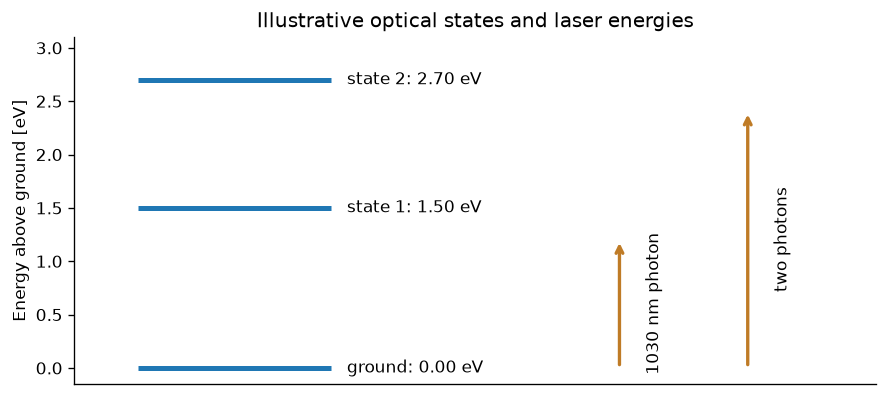

In [2]:
print("H0 [eV]:\n", model.hamiltonian.real)
print("mu [e Angstrom]:\n", model.dipole.real)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for level, label in zip(model.energies[:3], ["ground", "state 1", "state 2"]):
    ax.hlines(level, 0.2, 0.8, lw=3)
    ax.text(0.85, level, f"{label}: {level:.2f} eV", va="center")
for height, xpos, label in [
    (fundamental_ev, 1.7, "1030 nm photon"),
    (2 * fundamental_ev, 2.1, "two photons"),
]:
    ax.annotate(
        "",
        xy=(xpos, height),
        xytext=(xpos, 0),
        arrowprops={"arrowstyle": "->", "color": "#bf7b26", "lw": 2},
    )
    ax.text(xpos + 0.08, height / 2, label, rotation=90, va="center")
ax.set(
    xlim=(0, 2.5),
    ylim=(-0.15, 3.1),
    xticks=[],
    ylabel="Energy above ground [eV]",
    title="Illustrative optical states and laser energies",
)
fig.tight_layout()
fig.savefig(OUT / "levels.png", bbox_inches="tight")
plt.show()

## 1.2 Dipole block encoding (paper II.3, III.1.1)

Expand $\mu=\sum c_jP_j$ in Pauli strings. PREP creates weights
$\sqrt{|c_j|/s_\mu}$, SELECT applies signed/complex Pauli gates, and PREP† combines
branches coherently. The accepted block equals $\mu/s_\mu$,
$s_\mu=\sum|c_j|$. No built-in spectroscopy method is called.

Ancillas: 3 normalization: 1.6
Accepted-block error: 1.5201274094902937e-15


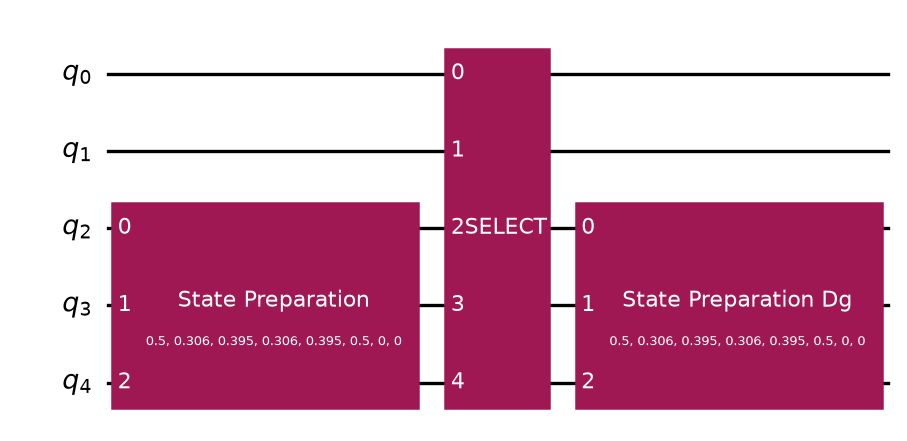

In [3]:
dipole = dipole_block(model)
print("Ancillas:", dipole.ancillas, "normalization:", dipole.scale)
print(
    "Accepted-block error:",
    np.max(abs(dipole.accepted() * dipole.scale - model.dipole)),
)
display(dipole.circuit.draw(output="mpl"))

## 1.3 Actual QSP phase sequences (paper II.4, III.1.2)

For a supplied window center $c$, rescale $\widetilde H=(H_0-cI)/R$ into $[-1,1]$.
Approximate an even erf-smoothed indicator by a bounded even Chebyshev polynomial
$p_d$. Fit phases in
$$
U_\Phi(x)=e^{i\phi_0Z}W(x)e^{i\phi_1Z}\cdots W(x)e^{i\phi_dZ},\qquad
W(x)=\begin{pmatrix}x&\sqrt{1-x^2}\\-\sqrt{1-x^2}&x\end{pmatrix}.
$$
The fit targets $\operatorname{Re}[U_{00}(x)]=p_d(x)$ on Chebyshev nodes and is
validated on independent grids. Extrema bound the target polynomial. The filter
uses an LCU of $U_\Phi$ and $U_\Phi^\dagger$ to select its Hermitian part.
The implementation explicitly builds the signal gates and phase rotations.
NumPy/SciPy support polynomial arithmetic and numerical optimization; no complete
QSP solver is called. This numerical fitter is for small degrees, not a general
high-degree synthesis guarantee.

**Scope:** windows are supplied around known toy energies; the paper's adaptive
spectral discovery, scalable chemistry oracles and amplitude estimation are not
implemented. A small diagonal square root constructs our signal oracle. The material calculation in Part 2 uses a separate small-instance resolvent circuit.

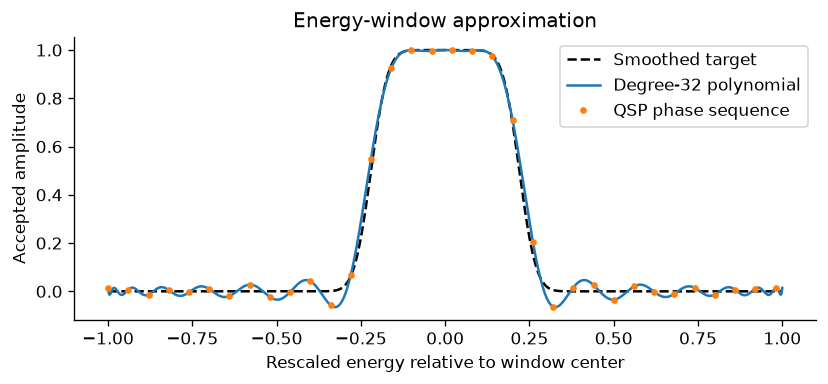

Phase synthesis grid error: 3.219646771412954e-15
Polynomial vs smooth-window grid error: 0.06977466764042628


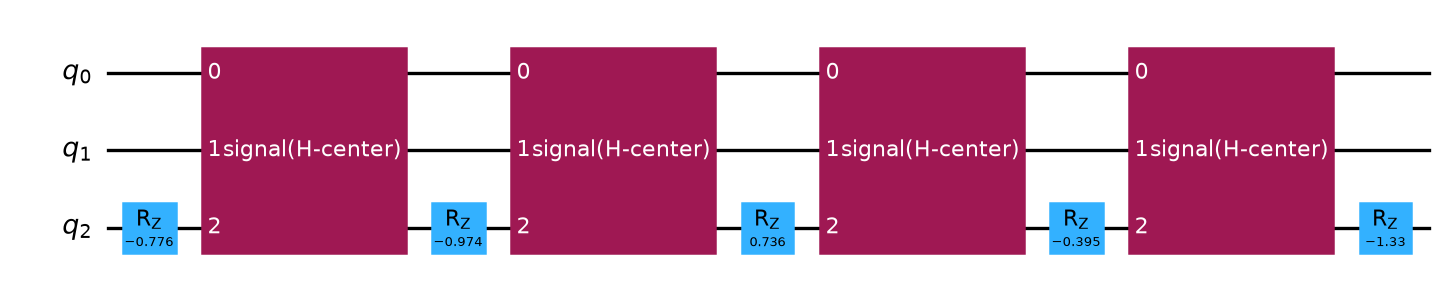

In [4]:
design = design_window(32)
x = np.linspace(-1, 1, 1001)
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(x, window(x), "k--", label="Smoothed target")
ax.plot(x, design.polynomial(x), label="Degree-32 polynomial")
ax.plot(x[::30], scalar_qsp(x[::30], design.phases), ".", label="QSP phase sequence")
ax.set(
    xlabel="Rescaled energy relative to window center",
    ylabel="Accepted amplitude",
    title="Energy-window approximation",
)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "qsp_filter.png", bbox_inches="tight")
plt.show()
print("Phase synthesis grid error:", design.synthesis_error)
print("Polynomial vs smooth-window grid error:", design.window_error)
raw_qsp, _ = qsp_signal_circuit(model, 1.5, 4)
display(raw_qsp.draw(output="mpl"))

## 1.4 Coherent dipole products and Hadamard readout (paper III.2)

Target $T_{21}=\langle g|\mu P_2\mu P_1\mu|g\rangle=0.12s$ for ideal filters.
Use approximate QSP windows and retain all normalization factors. Fresh ancilla
registers prevent failed branches from returning to the accepted block. All-zero
statevector amplitude yields the complex overlap; an actual Hadamard test checks
its real part. No intermediate measurements occur. Little endian ordering:
system q0,q1; work registers follow; optional Hadamard control is last.

In [5]:
product, scale, coherent = qsp_product(model, degree=32)
exact_product = (
    model.dipole[0, 2] * model.dipole[2, 1] * model.dipole[1, 0]
)  # analytic transition product
print("QSP product:", product, "Exact product:", exact_product)
print("Absolute filter-induced product error:", abs(product - exact_product))
print("Normalization:", scale, "product-circuit qubits:", coherent.num_qubits)
hadamard = overlap_circuit(qsp_sequence(model, degree=32), "real")
prob = Statevector.from_instruction(hadamard).probabilities([hadamard.num_qubits - 1])
assert np.isclose(scale * (prob[0] - prob[1]), product.real, atol=1e-9)
print("Explicit Hadamard check:", scale * (prob[0] - prob[1]))
# For Hermitian mu/filters, the reversed overlap is its conjugate.
products = {(2, 1): product, (1, 2): product.conjugate()}

QSP product: (0.11993532514322576-2.427632204916516e-16j) Exact product: (0.12+0j)
Absolute filter-induced product error: 6.467485677423557e-05
Normalization: 4.096000000000001 product-circuit qubits: 15
Explicit Hadamard check: 0.11993532514322582


## 1.5 Assemble full second-order response and validate independently

With $D_k(a,b)=k\hbar\omega-(E_a-E_b)+i\Gamma$, sum
$$
\beta=\sum_{mn}T_{mn}\left[
\frac1{D_2(m,g)D_1(n,g)}-\frac1{D_2(n,m)D_1(g,m)}
-\frac1{D_2(n,m)D_1(n,g)}+\frac1{D_2(g,n)D_1(g,m)}\right].
$$
All four commutator terms are retained. Only two ordered triples are nonzero for
this zero-diagonal model; exploiting that known sparsity is a toy assumption.
An independent reference evaluates density-matrix perturbation theory directly:
$\rho_1=-(\hbar\omega-L+i\Gamma)^{-1}[\mu,\rho_0]$,
$\rho_2=-(2\hbar\omega-L+i\Gamma)^{-1}[\mu,\rho_1]$,
$\beta=\mathrm{Tr}(\mu\rho_2)$ with $L\rho=[H_0,\rho]$.

1030 nm QSP-derived beta: (1.328481805711345+0.4643166695180682j)
Independent reference:   (1.329198186564183+0.46456705124724973j)
Relative numerical error: 0.0005389571397857259


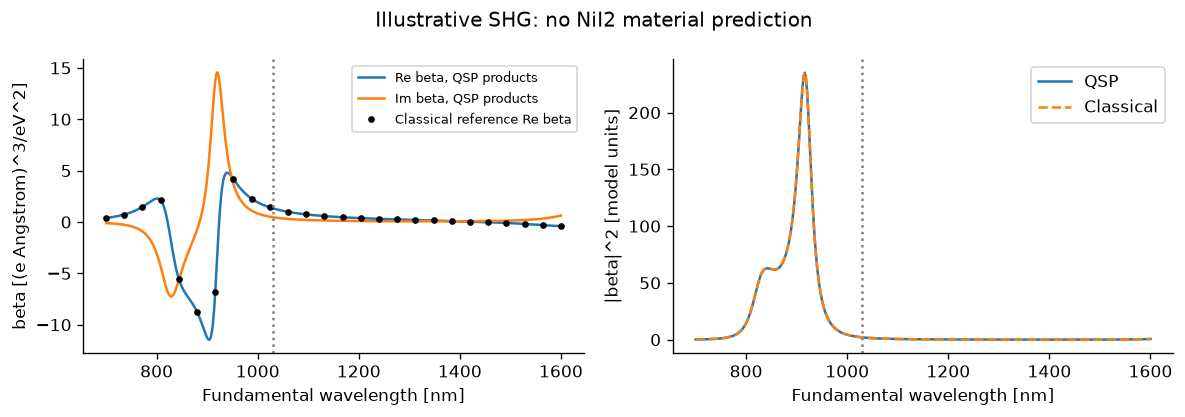

In [6]:
beta = beta_from_products(model, products, fundamental_ev, gamma_toy_ev)
reference = classical_beta(model, fundamental_ev, gamma_toy_ev)
print("1030 nm QSP-derived beta:", beta)
print("Independent reference:  ", reference)
print("Relative numerical error:", abs(beta - reference) / abs(reference))
wavelengths = np.linspace(700, 1600, 401)
quantum_curve = np.array(
    [
        beta_from_products(model, products, photon_energy(w), gamma_toy_ev)
        for w in wavelengths
    ]
)
classical_curve = np.array(
    [classical_beta(model, photon_energy(w), gamma_toy_ev) for w in wavelengths]
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(wavelengths, quantum_curve.real, label="Re beta, QSP products")
axes[0].plot(wavelengths, quantum_curve.imag, label="Im beta, QSP products")
axes[0].plot(
    wavelengths[::16],
    classical_curve.real[::16],
    "k.",
    label="Classical reference Re beta",
)
axes[0].set(ylabel="beta [(e Angstrom)^3/eV^2]")
axes[0].legend(fontsize=8)
axes[1].plot(wavelengths, abs(quantum_curve) ** 2, label="QSP")
axes[1].plot(wavelengths, abs(classical_curve) ** 2, "--", label="Classical")
axes[1].set(ylabel="|beta|^2 [model units]")
axes[1].legend()
for ax in axes:
    ax.axvline(1030, color="gray", ls=":")
    ax.set(xlabel="Fundamental wavelength [nm]")
fig.suptitle("Illustrative SHG: no NiI2 material prediction")
fig.tight_layout()
fig.savefig(OUT / "shg_response.png", bbox_inches="tight")
plt.show()

# 2. Quantum algorithm for the current Gao-state hybrid

This is the most complete **current declared approximation**, not a validated
“most accurate” bulk NiI₂ prediction. Its magnetic parameters come from Gao;
the optical electronic model retains Fan's parameters. The roles are distinct:
$$\beta_{ijk}(\omega)=\mathrm{Tr}
  [\rho_{Gao}\,\mathcal O^{optical}_{ijk}(\omega)].$$
Gao's meV spin Hamiltonian determines a correlated magnetic density. The
retained electronic energies and dipoles determine the optical response
operator at 1.20373 eV. A direct substitution of spin excitation energies into
electronic optical denominators would describe a different, unjustified model.
No raw electronic dipole is applied to the Gao spin Hilbert space.

## 2.1 Gao magnetic Hamiltonian and fixed input parameters

Implement the quantum S=1 realization
$$H_{Gao}=\sum_{i<j}\mathbf S_i^T[J_{n(ij)}I+J^r_{ij}]\mathbf S_j
   +B\sum_{\langle ij\rangle_{i<j}}(\mathbf S_i\cdot\mathbf S_j)^2
   +\tfrac12 A_{zz}\sum_i(S_i^z)^2.$$
The finite geometry has a center and six neighbors, open boundaries, and
12/6/3 first/second/third-neighbor pairs; dimension $3^7=2187$. Pair terms
are counted once. Anisotropic tensors are generated by C3 rotations from
the reference bond. The paper's semiclassical periodic spin-wave calculation
is not reproduced by this finite quantum cluster.

**Source choices:** Supplementary Table S1 is the primary bundle, including
J2=−0.32 meV; main Methods gives +0.32, retained as a sensitivity. Reference
axes follow the table caption (y along a reference bond, z out of plane),
despite surrounding text's “cubic” wording. The literal single-ion factor
1/2 is kept. These are explicit interpretations, not author confirmation.
Source: [Gao et al., Methods and Supplementary Table S1](https://doi.org/10.1038/s41586-024-07678-5).

In [7]:
from nii2_shg.angular_response import error_metrics
from nii2_shg.gao_reference import read_static_source
from nii2_shg.gao_spin_model import GaoSpinConfig, build_gao_h0
from nii2_shg.hybrid_response import (
    HybridStateConfig,
    oriented_pair_states,
    selected_state,
)

hybrid_report = json.loads((OUT / "hybrid_shg_report.json").read_text())
state_config = HybridStateConfig(**hybrid_report["state_config"])
gao_config = GaoSpinConfig(**hybrid_report["gao_config"])
tick = time.perf_counter()
magnetic_model = build_gao_h0(ROOT, gao_config)
magnetic_build_s = time.perf_counter() - tick
magnetic_h0 = magnetic_model["h0_ev"]
print(
    "Gao spin H0:", magnetic_h0.shape, "unit: eV; primary:", hybrid_report["gao_config"]
)
parameters = magnetic_model["parameters"]
lines = ["| Magnetic parameter | Value (meV) |", "|---|---:|"]
for label, value in [
    ("J1", parameters["spin_model"]["J1_meV"]),
    ("J2 (Table S1)", parameters["spin_model"]["supplementary_J2_meV"]),
    ("J3", parameters["spin_model"]["J3_meV"]),
    ("B", parameters["spin_model"]["B_meV"]),
    ("Azz (coefficient is Azz/2)", parameters["spin_anisotropy_meV"]["Azz"]),
]:
    lines.append(f"| {label} | {value} |")
for label, value in parameters["spin_anisotropy_meV"].items():
    if label != "Azz":
        lines.append(f"| {label} | {value} |")
display(Markdown("\n".join(lines)))

Gao spin H0: (2187, 2187) unit: eV; primary: {'j2_source': 'supplement', 'single_ion_factor': 0.5}


| Magnetic parameter | Value (meV) |
|---|---:|
| J1 | -5.03 |
| J2 (Table S1) | -0.32 |
| J3 | 3.95 |
| B | -0.89 |
| Azz (coefficient is Azz/2) | 0.44 |
| J1r_xx | -0.13 |
| J1r_yy | 0.82 |
| J1r_zz | -0.69 |
| J1r_xy | -0.96 |
| J3r_xx | 0.08 |
| J3r_yy | -0.02 |
| J3r_zz | -0.06 |
| J3r_xy | -0.045 |
| locator | Supplementary Table S1, printed page 8 (PDF page 9) |

## 2.2 Optical Hamiltonian, operator and spectroscopy settings

The retained nearest-bond electronic model has two Ni e_g shells and two I p
shells, 20 spin-orbitals/16 electrons, and 4845 Fock states. Ni t2g shells
are frozen. Fan's tabulated interactions, hopping and printed SOC convention
are retained. The negative Δ is an orbital-energy convention, not a negative
excitation gap. The SOC matrix/prose ordering discrepancy remains unresolved.
These optical-model parameters are **not** supplied by Gao's spin Hamiltonian.
Source: [Fan et al., Methods/Table 2](https://doi.org/10.1038/s41524-026-02184-w).

Use an ideal point-center dipole
$\boldsymbol\mu=-e\sum_p\mathbf r_p n_p$, with assumed Ni–I length 2.8 Å.
It obeys the Peierls relations $\bar J=i[H_e,\mu]$ and
$D=[\mu,[H_e,\mu]]$; consistency does not establish accurate optical matrix
elements. Orbital extent, missing t2g pathways and the complete Wannier/NTO
optical spectral weight remain limitations. Fan's printed static polarization
kernels are not substituted as calibrated optical dipoles.

Fundamental wavelength 1030 nm gives $\hbar\omega=1.20373$ eV and harmonic
515 nm. Assume Γ1=0.5 eV, Γ2=1 eV (the adiabatic $z,2z$ convention), not an
experimentally measured linewidth. T=1.63 K, q=0.138, normal tilt +55°,
one handedness and hκ=0.05 meV are fixed before angular comparison.

In [8]:
optical_parameters = json.loads(
    (ROOT / "data/nii2/fan2026_parameters.json").read_text()
)
lines = ["| Retained optical input | Value (eV) |", "|---|---:|"]
for group in ["local", "nearest_neighbor"]:
    for name, value in optical_parameters[group].items():
        lines.append(f"| {group}: {name} | {value} |")
display(Markdown("\n".join(lines)))
print(
    "Optical photon/gamma1/gamma2 (eV):",
    hybrid_report["photon_ev"],
    hybrid_report["optical_gamma1_ev"],
    hybrid_report["optical_gamma2_ev"],
)
print("Magnetic-state settings:", hybrid_report["state_config"])

| Retained optical input | Value (eV) |
|---|---:|
| local: U_Ni | 4.0 |
| local: U_I | 2.0 |
| local: J_H_Ni | 1.0 |
| local: J_H_I | 0.5 |
| local: lambda_Ni | 0.0 |
| local: lambda_I | 0.5 |
| local: Delta | -2.0 |
| nearest_neighbor: t1 | 0.77 |
| nearest_neighbor: t2 | 0.44 |
| nearest_neighbor: t3 | 0.89 |
| nearest_neighbor: v1 | 0.287 |
| nearest_neighbor: v2 | 0.566 |
| nearest_neighbor: r1 | 0.0 |
| nearest_neighbor: r2 | 0.0 |
| nearest_neighbor: r3 | 0.0 |

Optical photon/gamma1/gamma2 (eV): 1.203730081553398 0.5 1.0
Magnetic-state settings: {'temperature_k': 1.63, 'selector_mev': 0.05, 'q_rlu': 0.138, 'normal_tilt_deg': 55.0, 'handedness': 1, 'eigenstates': 24}


## 2.3 Single-domain correlated state and common-frame mapping

A finite cluster cannot automatically select a bulk helical domain. Condition
one domain with the explicitly assumed, time-reversal-even source
$$H_{selected}=H_{Gao}-h_\kappa\sum_{\langle ij\rangle}
  \sin(\mathbf q\cdot\boldsymbol\delta_{ij})\,
  \hat n\cdot(\mathbf S_i\times\mathbf S_j).$$
hκ=0.05 meV is about 1% of |J1|, not a published Gao coupling. Zero-source,
source-strength and handedness controls are reported in Section 3.4.
The density is thermal under this conditioned Hamiltonian, not unmodified H0.

Classical diagonalization of the lowest 24 states supplies the thermal trace
at 1.63 K, with a bound on omitted Boltzmann weight. Partial traces give all
12 nearest-neighbor pair densities, including quantum correlations. No
quantum thermal-state preparation is claimed. The state is conditional on
a finite source and open boundaries, not a solved bulk ordered phase.

Full-spin basis indices are little-endian base three, whereas optical pair
matrices use |mi,mj>. Reverse sites when a pair opposes its canonical optical
bond, then apply the S=1 rotation representing $R_b^T L^T$. L maps local cubic
components into lab x (along q), y (the chosen C2 axis), z (out of plane).
The Gao +y reference bond aligns with optical X. Four finite-cluster positions
per orientation are averaged; these are not different magnetic domains.
Their three complex response amplitudes are summed before squaring.

| Orientation | Averaged NN pairs | Trace | Purity |
|---|---:|---:|---:|
| Z | 4 | 1.00000000 | 0.481106 |
| X | 4 | 1.00000000 | 0.481078 |
| Y | 4 | 1.00000000 | 0.481119 |

Recomputed vs saved pair density, max Frobenius difference: 0.0
Thermal omitted-weight bound: 6.120702356643787e-31
Spin eigen-equation residual (eV): 3.22750372213368e-14


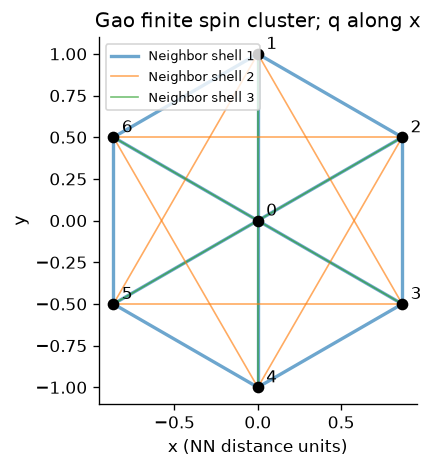

In [9]:
tick = time.perf_counter()
magnetic_state = selected_state(magnetic_model, state_config)
pair_states = oriented_pair_states(magnetic_model, magnetic_state)
magnetic_density_s = time.perf_counter() - tick
with np.load(OUT / "hybrid_pair_states.npz") as saved:
    saved_pairs = dict(zip(saved["names"].tolist(), saved["rho_spin"], strict=True))
    optical_spin_rotation = saved["optical_spin_rotation_16"].copy()
differences = []
lines = ["| Orientation | Averaged NN pairs | Trace | Purity |", "|---|---:|---:|---:|"]
for name, pair in pair_states.items():
    rho = pair["density"]
    differences.append(np.linalg.norm(rho - saved_pairs[name]))
    assert np.linalg.eigvalsh(rho).min() > -1e-10
    lines.append(
        f"| {name} | {pair['count']} | {np.trace(rho).real:.8f} | {np.trace(rho @ rho).real:.6f} |"
    )
assert max(differences) < 1e-7
display(Markdown("\n".join(lines)))
print("Recomputed vs saved pair density, max Frobenius difference:", max(differences))
print("Thermal omitted-weight bound:", magnetic_state["thermal_tail_bound"])
print("Spin eigen-equation residual (eV):", magnetic_state["eigen_residual_max_ev"])
fig, ax = plt.subplots(figsize=(5.3, 4))
plotted = set()
for bond in magnetic_model["bonds"]:
    points = magnetic_model["positions"][[bond["i"], bond["j"]]]
    shell = bond["shell"]
    ax.plot(
        points[:, 0],
        points[:, 1],
        color={1: "C0", 2: "C1", 3: "C2"}[shell],
        lw=2 if shell == 1 else 1,
        alpha=0.65,
        label=f"Neighbor shell {shell}" if shell not in plotted else None,
    )
    plotted.add(shell)
ax.scatter(*magnetic_model["positions"].T, c="black", zorder=3)
for i, (x, y) in enumerate(magnetic_model["positions"]):
    ax.annotate(str(i), (x + 0.05, y + 0.03))
ax.set(
    aspect="equal",
    xlabel="x (NN distance units)",
    ylabel="y",
    title="Gao finite spin cluster; q along x",
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "hybrid_geometry.png", dpi=160)
plt.show()

## 2.4 Quantum response operation and identical-input witness

The retained electronic low nine states are mapped to two S=1 spins through
the polar overlap with ionic triplets. Embed each Gao-derived pair density
into that electronic manifold; only the nine low energies are flattened for
frozen-spin optics. Excited electronic energies stay in the optical resolvents.
This mapping remains an explicit model approximation.

Vectorize the density column-wise and set
$$C=I\otimes\mu-\mu^T\otimes I,\qquad
  R_k=[k\hbar\omega-(E_a-E_b)+i\Gamma_k]^{-1}.$$
For one input/output polarization combination the circuit computes
$$\beta=\langle\!\langle\mu_{out}|R_2 C R_1 C|\rho\rangle\!\rangle.$$
Load the normalized Liouville vector |ρ⟩⟩/||ρ||F; apply four block encodings
with fresh ancillas, then inverse dipole-vector preparation. Restore all
block and state norms. One Hadamard control reads real/imaginary quadratures.
Six tensor components times three orientations require 18 circuit evaluations.

The 16-state demonstration uses 8 Liouville system qubits + 4 work qubits,
plus one control for Hadamard readout. The material circuit uses **dense
exact resolvent dilations**, not full-space QSP. Part 1 alone demonstrates
fitted QSP windows. Both are ideal simulations with classically constructed
oracles; loading a Liouville vector is not physical thermal-state preparation.

Same Gao-derived density: circuit / Hadamard / classical beta:
(-8.84366837483085e-08-7.433611587089288e-08j) (-8.843668384531425e-08-7.433611596074043e-08j) (-8.843668375580459e-08-7.433611587172768e-08j)
Base circuit qubits: 12 ; with Hadamard control: 13


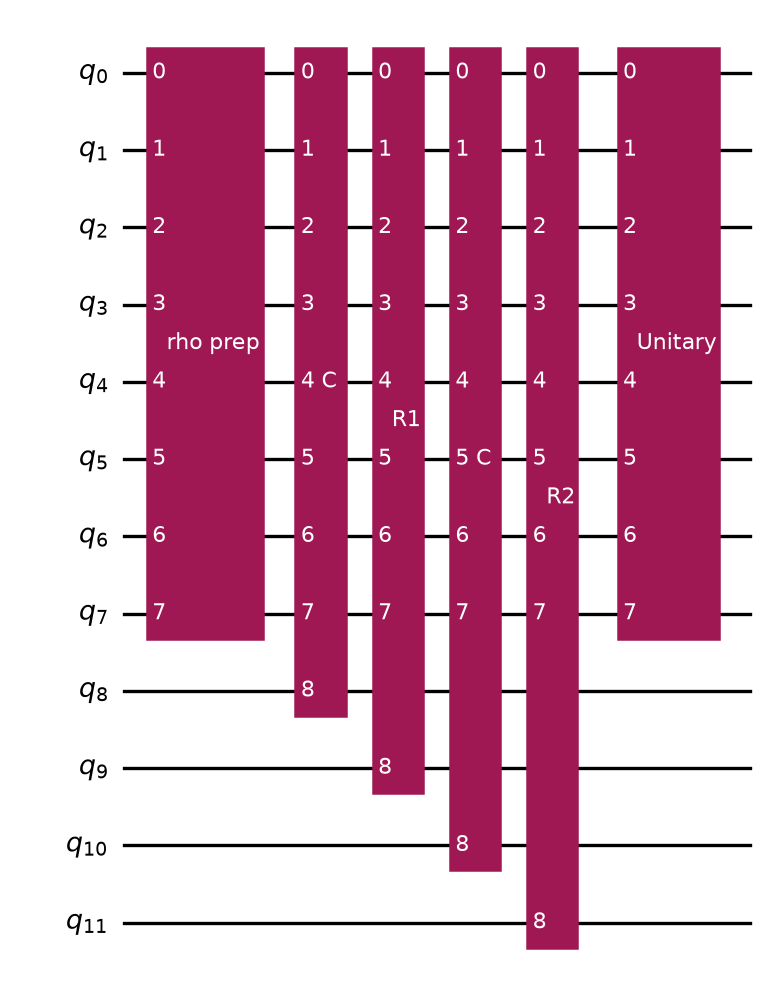

In [10]:
with np.load(OUT / "hybrid_circuits/Z_0_0.npz") as saved:
    witness_inputs = {k: saved[k].copy() for k in saved.files}
expected_density = (
    optical_spin_rotation @ pair_states["Z"]["density"] @ optical_spin_rotation.conj().T
)
assert np.allclose(witness_inputs["initial_rho"][:9, :9], expected_density, atol=1e-7)
kwargs = {
    "output_mu": witness_inputs["output_dipole"],
    "initial_rho": witness_inputs["initial_rho"],
    "second_gamma_factor": float(witness_inputs["second_gamma_factor"]),
}
material_witness = quantum_response(
    witness_inputs["energies"],
    witness_inputs["dipole"],
    hybrid_report["photon_ev"],
    hybrid_report["optical_gamma1_ev"],
    **kwargs,
)
material_direct = classical_response(
    witness_inputs["energies"],
    witness_inputs["dipole"],
    hybrid_report["photon_ev"],
    hybrid_report["optical_gamma1_ev"],
    **kwargs,
)
assert np.isclose(material_witness["beta"], material_direct, rtol=1e-7, atol=1e-12)
assert np.isclose(
    material_witness["hadamard_beta"], material_direct, rtol=1e-7, atol=1e-12
)
print("Same Gao-derived density: circuit / Hadamard / classical beta:")
print(material_witness["beta"], material_witness["hadamard_beta"], material_direct)
print(
    "Base circuit qubits:",
    material_witness["circuit"].num_qubits,
    "; with Hadamard control:",
    material_witness["circuit"].num_qubits + 1,
)
display(material_witness["circuit"].draw(output="mpl", fold=90))

## 2.5 Observable and angle convention

With incident $\mathbf e=(\cos\phi,\sin\phi)$ and analyzer
$\mathbf e_\perp=(-\sin\phi,\cos\phi)$, form
$P_i\propto\sum_{jk}\beta_{ijk}e_je_k$. The proxies are
$$I_\parallel\propto|P_x\cos\phi+P_y\sin\phi|^2,\qquad
  I_\perp\propto|-P_x\sin\phi+P_y\cos\phi|^2.$$
φ is measured from lab x (the chosen in-plane q direction), before the
reported common azimuth offset. The magnetic state stays fixed while
polarization rotates. Source columns B and K are parallel and crossed;
neither is swapped. Reversing the perpendicular-vector sign leaves intensity
unchanged. The microscopic β has model units (e Å)^3/eV². Detector µV
require a fitted gain here; absolute bulk χ^(2), propagation and power are
not predicted.

# 3. Comparison, disagreement and quantum advantage

## 3.1 Numerical correctness: separate two tests

For the toy, QSP-filter error is compared with an independent classical
density-matrix response as polynomial degree changes. For the hybrid,
quantum and classical must have **identical optical space and Gao density**.
Same-input agreement checks circuit arithmetic, not experimental validity.
The larger 512-state response is classical; it must not be presented as a
512-state quantum execution. No material calculation is claimed more accurate
merely because it happens to fit the measured lobes better.

**Tests and numerical tolerances.** Pytest checks known matrix products,
complex Hadamard phase, accepted block normalization, symmetry controls,
frame/site ordering, invalid inputs and independent density-matrix response.
A dedicated all-input operator test checks that fresh ancilla flags prevent a
previously rejected history from returning to the accepted branch. Work
ancillas are zero only in the accepted branch; unconditional cleanup of a
non-unitary block is neither assumed nor claimed.

Float64 exact small-matrix identities use absolute tolerances around 1e−12
(1e−11–2e−10 after chained response/readout normalization). Tiny spin-frame
identities use 1e−14; nearly saturated SVD square-root dilations allow 3e−8
unitarity error because square roots amplify roundoff near zero. QSP
phase-to-polynomial checks allow 1e−6 and report filter approximation error
separately. Recomputed magnetic pair densities allow 1e−7 against saved data
to accommodate degenerate-subspace numerics. These are numerical tolerances,
not experimental uncertainties or proofs of model accuracy. Absolute checks
are used for symmetry-zero signals instead of relative errors on noise.

In [11]:
toy_benchmark = run_benchmark(repeats=3)
(OUT / "benchmark.json").write_text(json.dumps(toy_benchmark, indent=2))
lines = [
    "| Toy QSP degree | Relative beta error | Phase synthesis (s) | CPU simulation median (s) |",
    "|---:|---:|---:|---:|",
]
for row in toy_benchmark["rows"]:
    lines.append(
        f"| {row['degree']} | {row['beta_relative_error']:.3g} | {row['phase_synthesis_s']:.4g} | {row['statevector_median_s']:.4g} |"
    )
display(Markdown("\n".join(lines)))
print(
    "Hybrid full tensor, quantum vs IDENTICAL 16-state classical:",
    hybrid_report["quantum_16"]["matched_classical_relative_tensor_error"],
)
print(
    "Witness absolute errors: statevector / Hadamard:",
    abs(material_witness["beta"] - material_direct),
    abs(material_witness["hadamard_beta"] - material_direct),
)

| Toy QSP degree | Relative beta error | Phase synthesis (s) | CPU simulation median (s) |
|---:|---:|---:|---:|
| 4 | 0.0831 | 0.01247 | 0.0008112 |
| 8 | 0.0474 | 0.01892 | 0.0008235 |
| 16 | 0.0109 | 0.06143 | 0.00078 |
| 32 | 0.000539 | 0.2346 | 0.0006945 |

Hybrid full tensor, quantum vs IDENTICAL 16-state classical: 4.67629626842495e-11
Witness absolute errors: statevector / Hadamard: 7.542423640925404e-18 1.2623489641295452e-16


## 3.2 Electronic-space convergence and the current accuracy limit

Hold the Gao magnetic density, optics and damping fixed; increase the common
optical response space. The 512-state result is the largest current internal
reference, not the full 4845-state solution. The 384→512 tensor change is
a sensitivity estimate, not a rigorous error bound. The 16-state quantum
tensor remains far from this reference. This reduction error is distinct
from circuit arithmetic and physical-model error.

| Optical states | Relative complex-tensor difference to 512 |
|---:|---:|
| 16 | 100.16% |
| 32 | 88.48% |
| 64 | 121.07% |
| 128 | 106.33% |
| 256 | 8.55% |
| 384 | 2.78% |
| 512 | 0.00% |

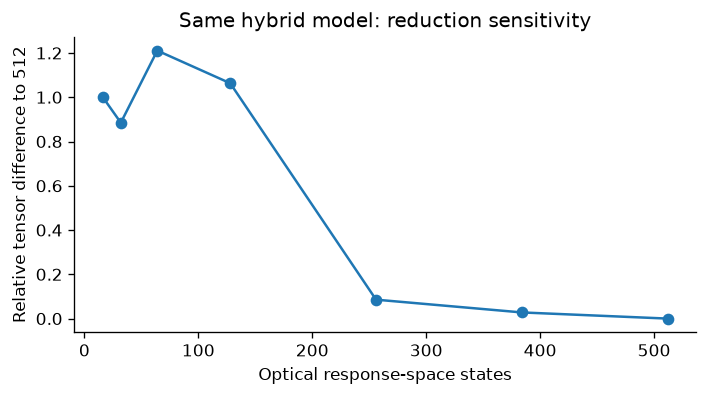

In [12]:
lines = [
    "| Optical states | Relative complex-tensor difference to 512 |",
    "|---:|---:|",
]
for row in hybrid_report["convergence"]:
    lines.append(
        f"| {row['states']} | {100 * row['tensor_relative_difference_to_512']:.2f}% |"
    )
display(Markdown("\n".join(lines)))
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(
    [r["states"] for r in hybrid_report["convergence"]],
    [r["tensor_relative_difference_to_512"] for r in hybrid_report["convergence"]],
    "o-",
)
ax.set(
    xlabel="Optical response-space states",
    ylabel="Relative tensor difference to 512",
    title="Same hybrid model: reduction sensitivity",
)
fig.tight_layout()
fig.savefig(OUT / "hybrid_convergence.png", dpi=160)
plt.show()

## 3.3 Comparison with Gao's static experimental data

Use Figure 2a, Sheet1 A3:R76, first temperature 1.63 K. Preserve all 73 rows,
including the duplicate 55° sample, without smoothing or label swaps. Gao
reports the probe rounded to 1.20 eV; 1030 nm is 1.20373 eV. The observable
is equilibrium static SHG, not pump-induced dynamics. Sample thickness is
about 100 nm; our model omits bulk optical propagation.

Fit one nonnegative detector gain shared by both channels and one common
azimuth. No optical tensor coefficient, J, selector strength or domain
mixture is fitted. All-data residual is descriptive. Six held-out 30° blocks
modulo 180° group duplicates, opposite angles and both channels together.
No point error bars are supplied, so no reduced χ² is reported. Reuse of
this dataset during model development means these are diagnostic blocked
scores, not fresh independent validation after model selection.

| Current hybrid calculation | All-data angular residual | Blocked held-out error |
|---|---:|---:|
| Quantum algorithm, 16 optical states | 77.45% | 88.51% |
| Classical optical reference, 512 states | 64.69% | 77.33% |

Train-only constant-per-channel baseline held-out relative error: 0.6768459863568148


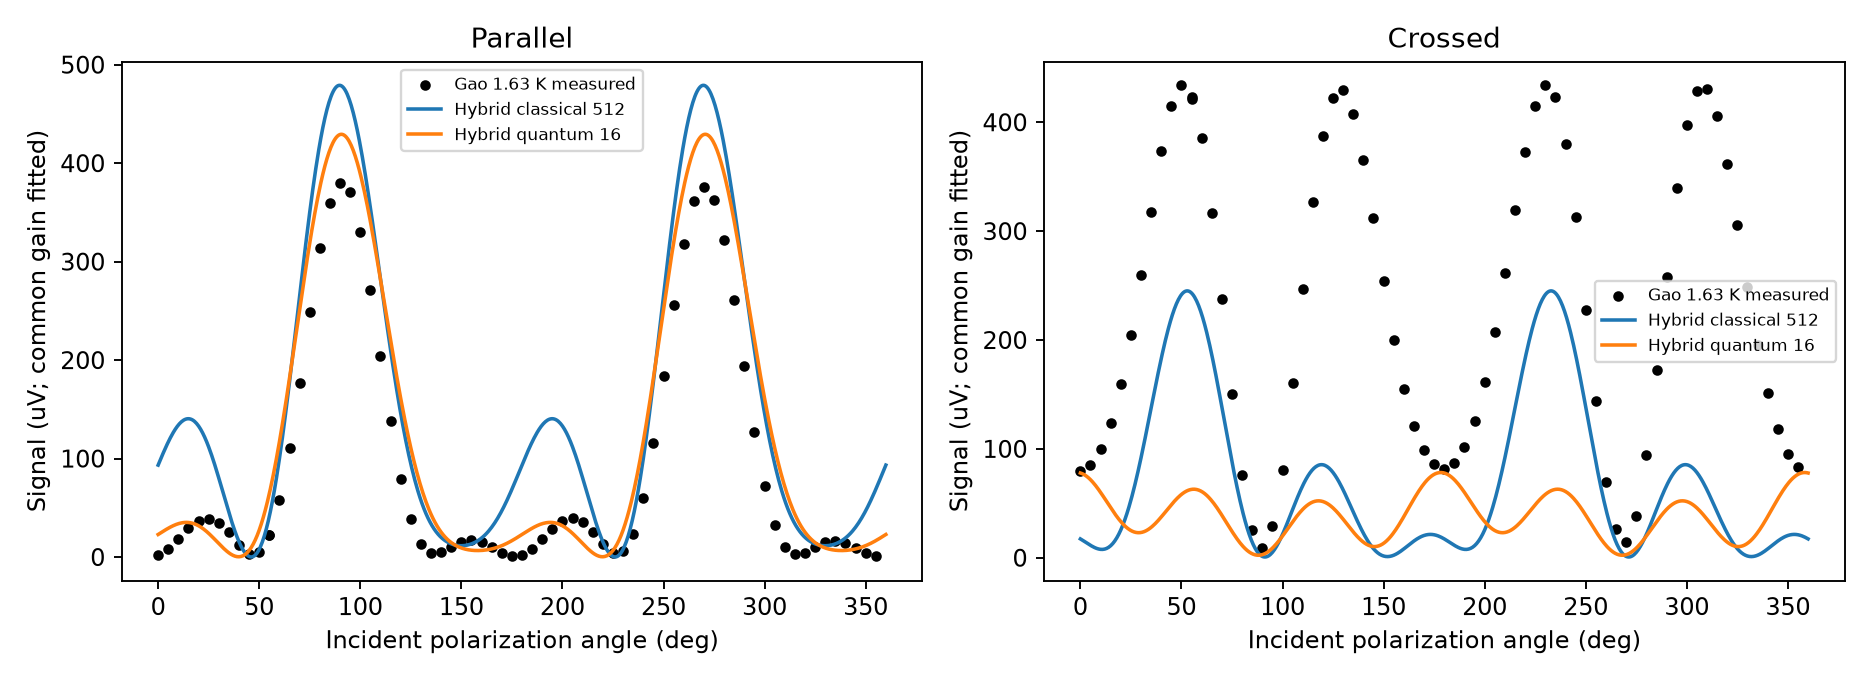

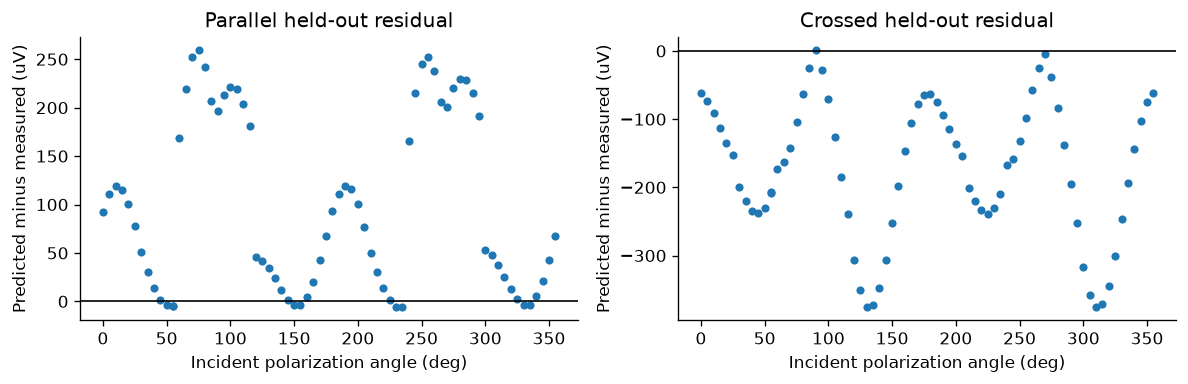

In [13]:
experimental = read_static_source(ROOT)
angles = np.array(experimental["angle_deg"])
observed = np.column_stack(
    [experimental["traces"][0]["parallel_uv"], experimental["traces"][0]["crossed_uv"]]
)
lines = [
    "| Current hybrid calculation | All-data angular residual | Blocked held-out error |",
    "|---|---:|---:|",
]
for label, case in [
    ("Quantum algorithm, 16 optical states", hybrid_report["quantum_16"]),
    ("Classical optical reference, 512 states", hybrid_report["classical_512"]),
]:
    score = case["comparison"]
    lines.append(
        f"| {label} | {100 * score['all_data_metrics']['joint']['relative_l2']:.2f}% | {100 * score['out_of_fold_metrics']['joint']['relative_l2']:.2f}% |"
    )
display(Markdown("\n".join(lines)))
folds = np.floor(np.mod(angles, 180) / 30).astype(int)
baseline = np.zeros_like(observed)
for fold in range(6):
    baseline[folds == fold] = observed[folds != fold].mean(axis=0)
baseline_metrics = error_metrics(observed, baseline)
print(
    "Train-only constant-per-channel baseline held-out relative error:",
    baseline_metrics["joint"]["relative_l2"],
)
display(Image(filename=str(OUT / "hybrid_shg_comparison.png")))
residuals = (
    np.array(hybrid_report["classical_512"]["comparison"]["out_of_fold_prediction_uv"])
    - observed
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for channel, label in enumerate(["Parallel", "Crossed"]):
    axes[channel].scatter(angles, residuals[:, channel], s=15)
    axes[channel].axhline(0, c="black", lw=1)
    axes[channel].set(
        title=label + " held-out residual",
        xlabel="Incident polarization angle (deg)",
        ylabel="Predicted minus measured (uV)",
    )
fig.tight_layout()
fig.savefig(OUT / "hybrid_residuals.png", dpi=160)
plt.show()

**The model still disagrees with experiment.** The 512-state reference has
64.69% all-data residual and 77.33% held-out error; the 16-state quantum
result has 77.45% and 88.51%. The train-only constant baseline is 67.68%
held-out, better than the current physical model. Thus a correct quantum
implementation has not produced an accurate material prediction. Absolute
amplitude is fitted out, so the remaining mismatch concerns angular shape
and relative channels, not just an unknown overall signal scale.

## 3.4 Sensitivities and physical sources of disagreement

Report controls of the same hybrid rather than select the best-looking fit.
Zero selector yields effectively zero inversion-odd response; do not normalize
its numerical noise. Weak-source amplitude is roughly linear in hκ, but its
normalized pattern changes little. Reversing handedness reverses amplitude
and preserves intensity. J2's unresolved sign changes the pattern substantially;
the complete Table S1 parameter set remains primary rather than choosing a
sign from this dataset.

In [14]:
lines = [
    "| Same-model state sensitivity | Relative amplitude norm | All-data residual | Held-out error |",
    "|---|---:|---:|---:|",
]
for row in hybrid_report["sensitivities"]:
    score = row["comparison"]
    amp = row["amplitude_norm_relative_to_primary"]
    if score is None:
        lines.append(f"| {row['name']} | {amp:.3g} | zero-signal control | — |")
    else:
        lines.append(
            f"| {row['name']} | {amp:.3g} | {100 * score['all_data_metrics']['joint']['relative_l2']:.2f}% | {100 * score['out_of_fold_metrics']['joint']['relative_l2']:.2f}% |"
        )
display(Markdown("\n".join(lines)))
print(
    "Opposite-handedness amplitude antisymmetry error:",
    hybrid_report["opposite_handedness_amplitude_antisymmetry_error"],
)

| Same-model state sensitivity | Relative amplitude norm | All-data residual | Held-out error |
|---|---:|---:|---:|
| No domain selector | 4.88e-11 | zero-signal control | — |
| Selector 0.005 meV | 0.1 | 64.69% | 77.33% |
| Selector 0.25 meV | 5 | 64.76% | 77.35% |
| Opposite handedness | 1 | 64.69% | 77.33% |
| Zero temperature | 1 | 64.69% | 77.33% |
| Opposite tilt branch | 0.993 | 64.46% | 77.47% |
| Main-text J2 sign | 2.41 | 57.11% | 68.84% |

Opposite-handedness amplitude antisymmetry error: 9.747164771660546e-11


| Remaining issue | Why it can affect the comparison |
|---|---|
| Finite, source-conditioned magnetic state | Seven open sites and a weak chirality source do not reproduce bulk spontaneous helical order; relative pair correlations can differ. |
| Source conventions | J2 sign, reference-axis wording and single-ion convention need clarification; changing them is a model change, not an analyzer correction. |
| Incomplete optical orbital model | Frozen t2g shells and point-center dipoles omit pathways and relative transition amplitudes/phases; internal gauge consistency does not establish optical accuracy. |
| Optical reduction | The small quantum response space is not converged; the largest classical space is only an internal reference. |
| Bulk optics and domains | Anisotropic propagation, interfaces and a full domain/state treatment can alter relative channels; one fitted gain does not account for all these effects. |

No tested diagnostic identifies a unique cause. The fitted detector gain is
not the quantum operator's block normalization. Missing absolute calibration
cannot automatically explain incorrect relative lobes.

## 3.5 Matched computational cost, resources and readout

Benchmark the **same 18 scalar responses in the same 16-state model**, with
inputs preloaded in one process. Classical timing includes direct perturbative
density-matrix response; quantum timing includes dense block/gate/state
construction and exact CPU statevector evaluation. Both exclude spin/electronic
preprocessing and input I/O. The timed quantum path has no Hadamard sampling;
the explicit witness above is a separate arithmetic check. Timings are local
implementation costs, not quantum hardware execution times.

In [15]:
cost = json.loads((OUT / "hybrid_benchmark.json").read_text())
lines = [
    "| Same 18 scalar responses | Median CPU seconds | Repeats |",
    "|---|---:|---:|",
    f"| Direct classical response | {cost['classical_median_s']:.6g} | {cost['classical_repeats']} |",
    f"| Dense quantum-circuit statevector path | {cost['quantum_statevector_median_s']:.6g} | {cost['quantum_repeats']} |",
]
display(Markdown("\n".join(lines)))
print(
    "CPU statevector / classical time ratio:",
    cost["statevector_to_classical_time_ratio"],
)
print("Matched benchmark response error:", cost["matched_relative_l2_error"])
print(
    "Classical optical-basis preprocessing (separate saved run, s):",
    cost["optical_basis_preprocessing_s_separate"],
)
print(
    "Classical Gao H0 build / selected-state pair construction (this run, s):",
    magnetic_build_s,
    magnetic_density_s,
)
print(
    "Platform:", cost["platform"], "Python:", cost["python"], "Qiskit:", cost["qiskit"]
)
print("Material circuit: 8 system + 4 work + optional 1 Hadamard control qubits.")
shots = cost["sampling_estimate"]
print("Witness normalized overlap magnitude:", shots["normalized_overlap_magnitude"])
print(
    "Naive Hadamard total shots for 10% complex relative RMS:",
    shots["total_shots_two_quadratures"],
)

| Same 18 scalar responses | Median CPU seconds | Repeats |
|---|---:|---:|
| Direct classical response | 0.000378625 | 31 |
| Dense quantum-circuit statevector path | 2.06429 | 3 |

CPU statevector / classical time ratio: 5452.075357955014
Matched benchmark response error: 4.930606634907027e-11
Classical optical-basis preprocessing (separate saved run, s): 23.820736291003413
Classical Gao H0 build / selected-state pair construction (this run, s): 0.1688778329989873 0.22208950005006045
Platform: macOS-26.6.1-arm64-arm-64bit Python: 3.12.6 Qiskit: 2.6.2
Material circuit: 8 system + 4 work + optional 1 Hadamard control qubits.
Witness normalized overlap magnitude: 2.6907459661981733e-08
Naive Hadamard total shots for 10% complex relative RMS: 552477499708393984


For independent ±1 Hadamard outcomes and β=s a, equal N shots for each
quadrature give approximately
$$\mathbb E|\widehat\beta-\beta|^2
  =s^2(2-|a|^2)/N.$$
The saved estimate applies this variance to the Z_0_0 witness for 10%
relative complex RMS error. Its tiny normalized overlap makes naive sampling
expensive. This is **not** an optimized or fundamental hardware lower bound:
different encodings, symmetry use or fault-tolerant readout could change it.
Amplitude estimation/amplification and device noise are not implemented.
Exact statevector agreement therefore does not establish shot-feasible accuracy.

Dense Liouville matrices also prevent straightforward scaling: K electronic
states require K² system amplitudes, while an explicitly stored block gate
has O(K⁴) entries. Calling such a matrix a block encoding does not make its
construction efficient. This is why the 512-state classical result is not
quietly relabeled as a 512-state quantum execution.

### 3.5.1 Gate counts, compilation, oracle work and success probabilities

Compile the toy repeated-signal circuit and its small supporting components
to **u/cx**, **all-to-all connectivity**, optimization level **1**, seed **7**.
Report actual raw repeated-signal CX/depth versus polynomial degree. The
accepted filter is also synthesized from its small dense matrix: those
separate counts include LCU PREP/SELECT/UNPREP but can hide query growth.
They must not be used as scalable oracle costs. Component-sum counts below
describe the base product, not a fully compiled controlled-Hadamard circuit.
Ground preparation is |00> only for this supplied toy example.

Simulator: `qiskit.quantum_info.Statevector`, ideal CPU, **zero executed
measurement shots**. Material resources are reported at logical block level
because physical synthesis of the large dense blocks is not attempted.
Classical oracle construction/state loading are counted separately from
compiled gate counts and simulator wall time.

| Degree | Raw signal calls | Raw QSP CX / depth | Base product component-sum CX | Work qubits | Postselection success |
|---:|---:|---:|---:|---:|---:|
| 4 | 4 | 40 / 77 | 344 | 13 | 0.0067131 |
| 8 | 8 | 80 / 153 | 344 | 13 | 0.00485132 |
| 16 | 16 | 160 / 305 | 344 | 13 | 0.00281106 |
| 32 | 32 | 320 / 609 | 344 | 13 | 0.00341703 |

Basis / connectivity / optimization / seed: ['u', 'cx'] all-to-all; coupling_map=None 1 7
Toy system / product total / Hadamard total qubits: 2 15 16
Two-filter unoptimized controlled-signal count: 128
Expected attempts IF generating a postselected state: 292.65179519816076
Compilation CPU seconds (raw QSP / dense filters / dipole): 0.005570750043261796 0.00579766696318984 0.045824917033314705
Material logical resources: {'electronic_states': 16, 'liouville_system_qubits': 8, 'fresh_work_qubits': 4, 'hadamard_control_qubits': 1, 'base_operations': ['density loading', 'C', 'R1', 'C', 'R2', 'dipole readout'], 'physical_basis_synthesis': 'not attempted for large dense material blocks; no physical material gate count claimed', 'all_18_evaluations': '18 base overlaps; one additional real+imag ideal Hadamard witness in saved calculator; no hardware samples'}


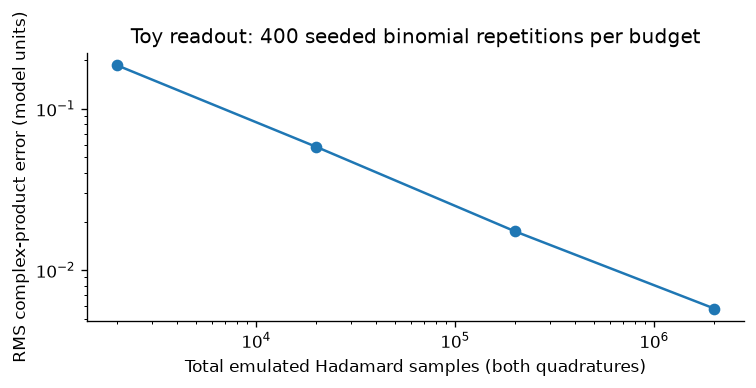

In [16]:
from nii2_shg.benchmarks import run_benchmark
from nii2_shg.resources import collect_resources

resource_report = collect_resources()
(OUT / "circuit_resources.json").write_text(json.dumps(resource_report, indent=2))
lines = [
    "| Degree | Raw signal calls | Raw QSP CX / depth | Base product component-sum CX | Work qubits | Postselection success |",
    "|---:|---:|---:|---:|---:|---:|",
]
for row in resource_report["rows"]:
    lines.append(
        f"| {row['degree']} | {row['raw_sequence_signal_calls']} | {row['raw_qsp']['cx']} / {row['raw_qsp']['depth']} | {row['base_product_component_sum_cx']} | {row['product_work_qubits']} | {row['accepted_work_zero_probability']:.6g} |"
    )
display(Markdown("\n".join(lines)))
row = resource_report["rows"][-1]
print(
    "Basis / connectivity / optimization / seed:",
    resource_report["basis_gates"],
    resource_report["connectivity"],
    resource_report["optimization_level"],
    resource_report["seed_transpiler"],
)
print(
    "Toy system / product total / Hadamard total qubits:",
    row["product_system_qubits"],
    row["product_total_qubits"],
    row["hadamard_total_qubits"],
)
print(
    "Two-filter unoptimized controlled-signal count:",
    row["two_filters_unoptimized_controlled_signal_calls"],
)
print(
    "Expected attempts IF generating a postselected state:",
    row["expected_attempts_if_postselecting_state"],
)
print(
    "Compilation CPU seconds (raw QSP / dense filters / dipole):",
    row["raw_qsp"]["compile_s"],
    row["dense_realpart_filter_1"]["compile_s"]
    + row["dense_realpart_filter_2"]["compile_s"],
    resource_report["dipole"]["compile_s"],
)
print("Material logical resources:", resource_report["material_logical_resources"])
toy_benchmark = run_benchmark(degrees=(32,), repeats=3)
(OUT / "toy_benchmark.json").write_text(json.dumps(toy_benchmark, indent=2))
sample_rows = toy_benchmark["sampling"]
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.loglog(
    [r["total_shots"] for r in sample_rows],
    [r["rms_statistical_error"] for r in sample_rows],
    "o-",
)
ax.set(
    xlabel="Total emulated Hadamard samples (both quadratures)",
    ylabel="RMS complex-product error (model units)",
    title="Toy readout: 400 seeded binomial repetitions per budget",
)
fig.tight_layout()
fig.savefig(OUT / "sampling_resources.png", dpi=160)
plt.show()

The sampling sweep is **classical binomial emulation** from circuit-derived
probabilities (seed 7), not a hardware or shot-backend run. N samples per
real/imaginary quadrature cost 2N executions. The material witness's analytic
variance estimate above concerns the current dense readout, not an optimized
fault-tolerant resource bound.

A postselected state-generation procedure would need mean 1/p attempts with
success p. Hadamard overlap estimation retains failure branches coherently;
its small-overlap penalty is already in the shot variance and is **not**
multiplied again by 1/p. Fresh flags preserve phase and prevent failed
histories from being recycled into success. Compiling a dense SELECT matrix
is supporting small-instance synthesis, not a free or scalable oracle.

## 3.6 What quantum advantage means here

**Demonstrated advantage: none.** The small direct classical calculation is
faster on this CPU. Spin density, optical reduction and dense oracles are
constructed classically; the material circuit then evaluates a small projected
problem. Neither ideal simulation nor agreement with a classical solver is
evidence of faster or more accurate prediction than classical computation.

**Potential advantage:** on a large correlated many-electron problem, efficient
Hamiltonian/dipole block encodings and prepared states could permit coherent
excitation/filtering and selected response estimation without explicitly
enumerating all intermediate eigenstates. QSP can target energy windows and
repeat this structure for nonlinear order. This is the motivation of the
[fault-tolerant response algorithm](https://arxiv.org/html/2404.01454v1),
not a speedup established by this implementation.

| Requirement for a useful advantage | Status in this project |
|---|---|
| Efficient many-body Hamiltonian/dipole oracles | Replaced by small dense matrices; scalable construction not demonstrated. |
| Affordable correlated-state preparation | Gao density and electronic reduction computed classically. |
| Controlled optical approximation | Toy QSP checked; material resolvents exact only inside an unconverged reduced space. |
| Feasible measurement precision | One ideal Hadamard witness; sampling estimate exposes a small-overlap bottleneck. |
| Fair competing classical calculation | Matched small-instance timings measured; no matched large-scale speed comparison. |
| Accurate physical model | Conditional finite cluster and incomplete optics still disagree with experiment. |

Logarithmic state-register size is a representation benefit, not proof of an
end-to-end exponential speedup. State preparation, normalization, energy
resolution, readout precision and fault-tolerant overhead must all be counted.
Classical sparse/Krylov/cluster methods can also avoid naive full diagonalization.
The current result demonstrates quantum-response primitives and their numerical
correctness; potential advantage remains a future scaling question.

## 3.7 Scope of the literature comparison

Gao supplies the magnetic model and static experimental reference. Fan supplies
retained electronic parameters. Mou motivates effective optical spin operators
but uses a different electronic/NTO model; its Figure 4 fits Song's dataset,
not this Gao trace. No matching complex response matrices, author runtime logs
or hardware measurements have been obtained to support accuracy/speed claims
against those calculations. The measured angular data are genuine; fitted
scale/azimuth and every physical-model assumption are reported separately.

# 4. Summary

The illustrative calculation implements QSP-filtered SHG with an independent
classical check. The single material calculation combines a Gao-derived,
single-domain-conditioned magnetic density with a retained electronic optical
operator. Gao spin energies determine the state; electronic excitation energies
remain in optical denominators.

The material quantum circuit agrees with the identical 16-state classical
response, but that reduction is inadequate. The 512-state reference gives
64.69% angular residual and 77.33% held-out error. Thus the current model does
not quantitatively reproduce the experimental SHG pattern.

**Quantum advantage is not demonstrated.** The measured small classical
response is faster; dense oracles, classical preprocessing and sampling costs
block a scalability claim. The paper's coherent filtering strategy motivates
a possible advantage for larger correlated problems under efficient-oracle,
state-preparation and readout assumptions.

Next evidence needed: clarify Gao conventions, validate the bulk domain/state,
obtain complete optical operators and demonstrate response-space convergence.
These physical and numerical issues must be resolved before experimental
agreement can be used to assess a predictive quantum material calculation.

In [17]:
summary = {
    "model": "Gao spin density / retained electronic optical operator hybrid",
    "temperature_k": state_config.temperature_k,
    "domain_selector_mev": state_config.selector_mev,
    "domain_count": 1,
    "physical_parameters_fitted": False,
    "quantum_vs_same_16_classical_relative_error": hybrid_report["quantum_16"][
        "matched_classical_relative_tensor_error"
    ],
    "hybrid512_all_data_relative_l2": hybrid_report["classical_512"]["comparison"][
        "all_data_metrics"
    ]["joint"]["relative_l2"],
    "hybrid512_heldout_relative_l2": hybrid_report["classical_512"]["comparison"][
        "out_of_fold_metrics"
    ]["joint"]["relative_l2"],
    "quantum_optical_reduction_converged": False,
    "validated_bulk_prediction": False,
    "quantum_computational_advantage_demonstrated": False,
    "timing_scope": cost["scope"],
    "sampling_is_hardware_measurement": False,
    "toy_qsp_relative_error": abs(beta - reference) / abs(reference),
}
(OUT / "project_status.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "model": "Gao spin density / retained electronic optical operator hybrid",
  "temperature_k": 1.63,
  "domain_selector_mev": 0.05,
  "domain_count": 1,
  "physical_parameters_fitted": false,
  "quantum_vs_same_16_classical_relative_error": 4.67629626842495e-11,
  "hybrid512_all_data_relative_l2": 0.6469079224622467,
  "hybrid512_heldout_relative_l2": 0.7733037205968958,
  "quantum_optical_reduction_converged": false,
  "validated_bulk_prediction": false,
  "quantum_computational_advantage_demonstrated": false,
  "timing_scope": "same-process, same 18 current-model scalar optical responses, preloaded inputs",
  "sampling_is_hardware_measurement": false,
  "toy_qsp_relative_error": 0.0005389571397857259
}
